In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
DATA_PATH = Path("../data/processed/rentals_engineered.csv")
MODEL_PATH = Path("../models/rent_price_model.joblib")

df = pd.read_csv(DATA_PATH)

model = joblib.load(MODEL_PATH)

print("Dataset loaded:", df.shape)
print("Trained model loaded successfully!")

Dataset loaded: (17890, 15)
Trained model loaded successfully!


In [4]:
model = joblib.load("../models/rent_price_model.joblib")

print("Trained model loaded successfully!")

Trained model loaded successfully!


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
import joblib

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

DATA_PATH = Path("../data/processed/rentals_engineered.csv")
MODEL_PATH = Path("../models/rent_price_model.joblib")

df = pd.read_csv(DATA_PATH)
model = joblib.load(MODEL_PATH)

print("Dataset loaded:", df.shape)
print("Model loaded successfully!")

Dataset loaded: (17890, 15)
Model loaded successfully!


In [6]:
df["price"] = pd.to_numeric(df["price"], errors="coerce")
df = df.dropna(subset=["price"])

X = df.drop(
    columns=["price", "url", "name", "amenities"],
    errors="ignore"
)

y = df["price"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (17890, 14)
Target: (17890,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 14312
Testing records: 3578


In [8]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison["Error"] = (
    comparison["Actual Price"]
    - comparison["Predicted Price"]
)

comparison["Absolute Error"] = comparison["Error"].abs()

comparison.head(10)

,Actual Price,Predicted Price,Error,Absolute Error
0,2000,1955.642100,44.357900,44.357900
1,2500,3339.800992,-839.800992,839.800992
2,1500,851.361131,648.638869,648.638869
3,1000,1227.446825,-227.446825,227.446825
4,4000,5097.299397,-1097.299397,1097.299397
5,3500,3483.899167,16.100833,16.100833
6,5000,4433.563492,566.436508,566.436508
7,3000,4180.392063,-1180.392063,1180.392063
8,8000,12823.683464,-4823.683464,4823.683464
9,1200,829.357143,370.642857,370.642857


In [9]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"MAE:  GHS {mae:,.2f}")
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: GHS {rmse:,.2f}")
print(f"R²:   {r2:.4f}")

MODEL EVALUATION RESULTS
------------------------
MAE:  GHS 2,978.01
MSE:  32,885,442.88
RMSE: GHS 5,734.58
R²:   0.7175


In [10]:
residuals = y_test - y_pred

print("Residual statistics:")
print(residuals.describe())

Residual statistics:
count     3578.000000
mean       156.822075
std       5733.239610
min     -33227.292732
25%      -1252.300840
50%       -185.567970
75%        661.187098
max      46229.563369
Name: price, dtype: float64


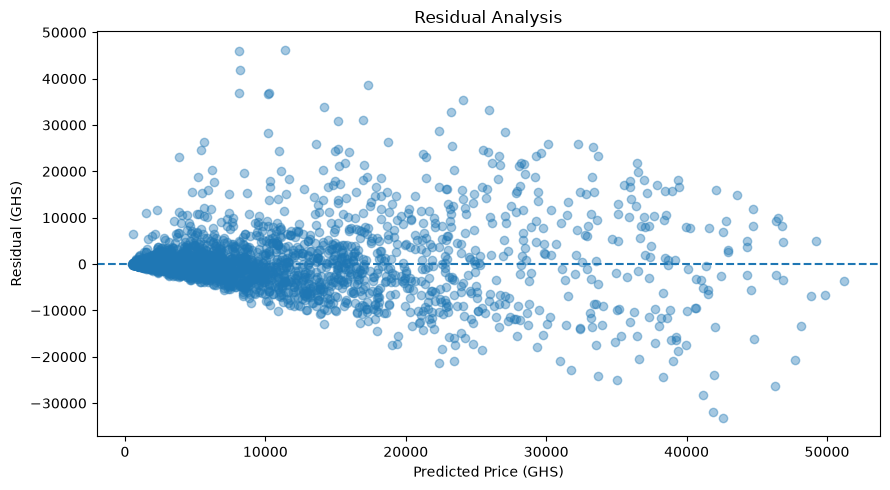

In [11]:
plt.figure(figsize=(9, 5))

plt.scatter(y_pred, residuals, alpha=0.4)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Price (GHS)")
plt.ylabel("Residual (GHS)")
plt.title("Residual Analysis")

plt.tight_layout()
plt.show()

In [12]:
comparison.sort_values(
    by="Absolute Error",
    ascending=False
).head(10)


,Actual Price,Predicted Price,Error,Absolute Error
925,57600,11370.436631,46229.563369,46229.563369
2960,54000,8088.643260,45911.356740,45911.356740
3178,50070,8169.171810,41900.828190,41900.828190
2392,56000,17343.895655,38656.104345,38656.104345
2211,47220,10285.065190,36934.934810,36934.934810
1383,45000,8124.233651,36875.766349,36875.766349
2158,46890,10166.144190,36723.855810,36723.855810
490,59524,24056.762357,35467.237643,35467.237643
343,48000,14149.646964,33850.353036,33850.353036
1432,59200,25896.486746,33303.513254,33303.513254


In [13]:
# Reconstruct the worst prediction records
worst_cases = X_test.copy()

worst_cases["Actual Price"] = y_test
worst_cases["Predicted Price"] = pd.Series(
    y_pred,
    index=X_test.index
)

worst_cases["Residual"] = (
    worst_cases["Actual Price"]
    - worst_cases["Predicted Price"]
)

worst_cases["Absolute Error"] = (
    worst_cases["Residual"].abs()
)

# Display the 10 largest errors
worst_cases = worst_cases.sort_values(
    by="Absolute Error",
    ascending=False
)

worst_cases.head(10)

,listing_type,category,bedrooms,bathrooms,floor_area,location,condition,region,locality,parking_space,is_furnished,lat,lng,amenities_count,Actual Price,Predicted Price,Residual,Absolute Error
651,rentals,Townhouse,2.0,2.0,180.0,"Greater Accra, East Legon",New,Greater Accra,East Legon,0,Unfurnished,5.635828,-0.161359,13,57600,11370.436631,46229.563369,46229.563369
11057,rentals,Townhouse,3.0,3.0,155.0,"Greater Accra, Adjiriganor, Otano",New,Greater Accra,Adjiriganor,0,Unfurnished,5.655887,-0.121453,11,54000,8088.643260,45911.356740,45911.356740
9396,rentals,Flats,3.0,3.0,900.0,"Greater Accra, Ashomang Estate",New,Greater Accra,Ashomang Estate,0,Semi-Furnished,5.688724,-0.227023,18,50070,8169.171810,41900.828190,41900.828190
15902,rentals,Townhouse,4.0,4.0,120.0,"Greater Accra, Ridge",Used,Greater Accra,Ridge,0,Furnished,5.814284,0.074677,16,56000,17343.895655,38656.104345,38656.104345
10300,rentals,Detached,5.0,5.0,255.0,"Greater Accra, Ashaley Botwe, Nmai-Dzorn",Used,Greater Accra,Ashaley Botwe,0,Semi-Furnished,5.686459,-0.114666,8,47220,10285.065190,36934.934810,36934.934810
12165,rentals,Detached,3.0,4.0,18.0,"Greater Accra, Ashaley Botwe",New,Greater Accra,Ashaley Botwe,0,Unfurnished,5.680213,-0.137248,9,45000,8124.233651,36875.766349,36875.766349
700,rentals,Flats,4.0,3.0,70.0,"Greater Accra, Accra Metropolitan",Renovated,Greater Accra,Accra Metropolitan,0,Unfurnished,5.545941,-0.210399,5,46890,10166.144190,36723.855810,36723.855810
12545,rentals,Detached,5.0,5.0,3000.0,"Greater Accra, East Legon, American House",Used,Greater Accra,East Legon,0,Unfurnished,5.643989,-0.148530,2,59524,24056.762357,35467.237643,35467.237643
8156,rentals,Detached,5.0,6.0,100.0,"Western Region, Takoradi",New,Western Region,Takoradi,0,Furnished,4.901579,-1.783097,18,48000,14149.646964,33850.353036,33850.353036
14926,rentals,Flats,2.0,2.0,100.0,"Greater Accra, Cantonments, US Embassy Area",New,Greater Accra,Cantonments,0,Furnished,5.579480,-0.170623,13,59200,25896.486746,33303.513254,33303.513254


In [14]:
print("Price distribution:")

print(
    df["price"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)


Price distribution:
count    17890.000000
mean      7999.412968
std      10404.773528
min        416.000000
25%       1700.000000
50%       3500.000000
75%       9872.250000
90%      21935.000000
95%      32000.000000
99%      49500.000000
max      59524.000000
Name: price, dtype: float64


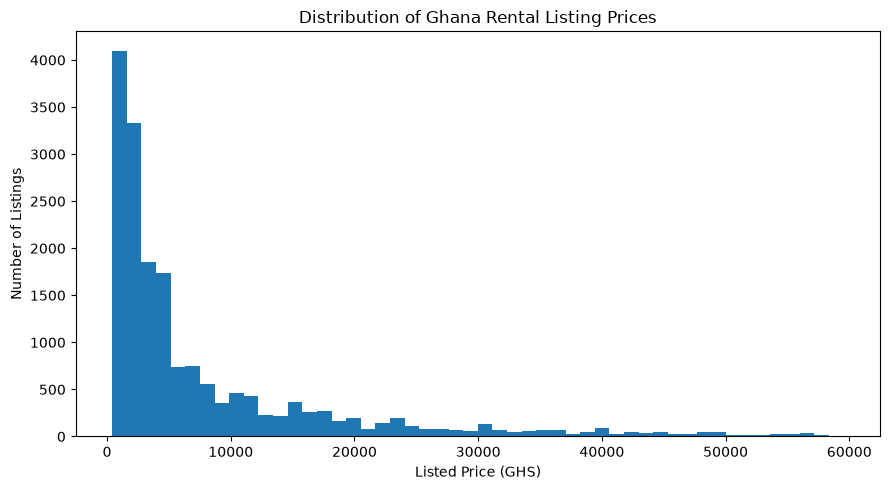

In [15]:
plt.figure(figsize=(9, 5))

plt.hist(df["price"], bins=50)

plt.xlabel("Listed Price (GHS)")
plt.ylabel("Number of Listings")

plt.title("Distribution of Ghana Rental Listing Prices")

plt.tight_layout()
plt.show()

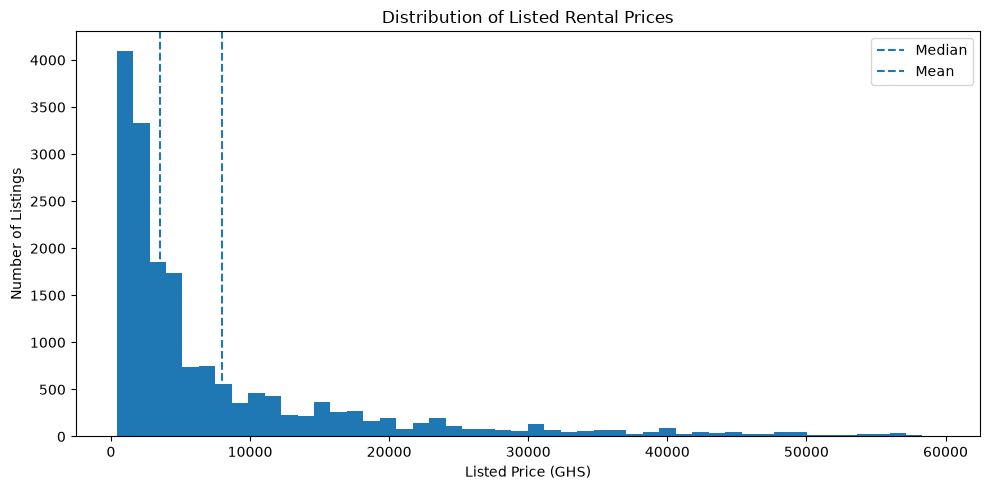

In [16]:
plt.figure(figsize=(10, 5))

plt.hist(df["price"], bins=50)

plt.axvline(
    df["price"].median(),
    linestyle="--",
    label="Median"
)

plt.axvline(
    df["price"].mean(),
    linestyle="--",
    label="Mean"
)

plt.xlabel("Listed Price (GHS)")
plt.ylabel("Number of Listings")

plt.title("Distribution of Listed Rental Prices")

plt.legend()
plt.tight_layout()
plt.show()

In [17]:
expensive_listings = df.sort_values(
    by="price",
    ascending=False
)

expensive_listings[
    [
        "price",
        "bedrooms",
        "bathrooms",
        "category",
        "region",
        "locality",
        "floor_area"
    ]
].head(15)

,price,bedrooms,bathrooms,category,region,locality,floor_area
12545,59524,5.0,5.0,Detached,Greater Accra,East Legon,3000.0
5098,59500,4.0,4.0,Detached,Greater Accra,East Legon,240.0
3095,59267,2.0,3.0,Flats,Greater Accra,Spintex,140.0
2587,59250,3.0,4.0,Detached,Greater Accra,Cantonments,100.0
14926,59200,2.0,2.0,Flats,Greater Accra,Cantonments,100.0
3476,59000,4.0,4.0,Detached,Greater Accra,East Legon,295.0
3563,59000,5.0,5.0,Mansion,Greater Accra,Cantonments,650.0
13010,58500,5.0,5.0,Detached,Greater Accra,Accra Metropolitan,145.0
13402,58492,4.0,5.0,Mansion,Greater Accra,Cantonments,160.0
17888,58300,4.0,5.0,Detached,Greater Accra,Teshie,100.0


In [18]:
print("Floor area statistics:")
print(df["floor_area"].describe(percentiles=[
    0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99
]))

Floor area statistics:
count    17890.000000
mean       556.094913
std       1044.912578
min         10.000000
1%          10.000000
5%          14.000000
25%        100.000000
50%        145.000000
75%        600.000000
90%       1200.000000
95%       3000.000000
99%       5000.000000
max       5000.000000
Name: floor_area, dtype: float64


In [19]:
small_area = df[df["floor_area"] <= 50]

print("Number of listings with floor area <= 50:")
print(len(small_area))

small_area[
    ["price", "bedrooms", "bathrooms", "category",
     "locality", "floor_area"]
].head(20)

Number of listings with floor area <= 50:
3338


,price,bedrooms,bathrooms,category,locality,floor_area
3,2500,3.0,3.0,Detached,Teshie,17.0
7,2000,1.0,1.0,Flats,Adenta,10.0
8,1800,2.0,3.0,Flats,Teshie,15.0
11,1000,1.0,1.0,Flats,Teshie,15.0
18,1500,2.0,2.0,Flats,Nungua,17.0
21,2300,2.0,2.0,Flats,East Legon,14.0
26,2000,2.0,1.0,Flats,Dome,20.0
38,600,1.0,1.0,Flats,Taifa-Burkina,14.0
41,8000,1.0,1.0,Flats,Adjiriganor,12.0
42,1000,2.0,1.0,Flats,Accra Metropolitan,21.0


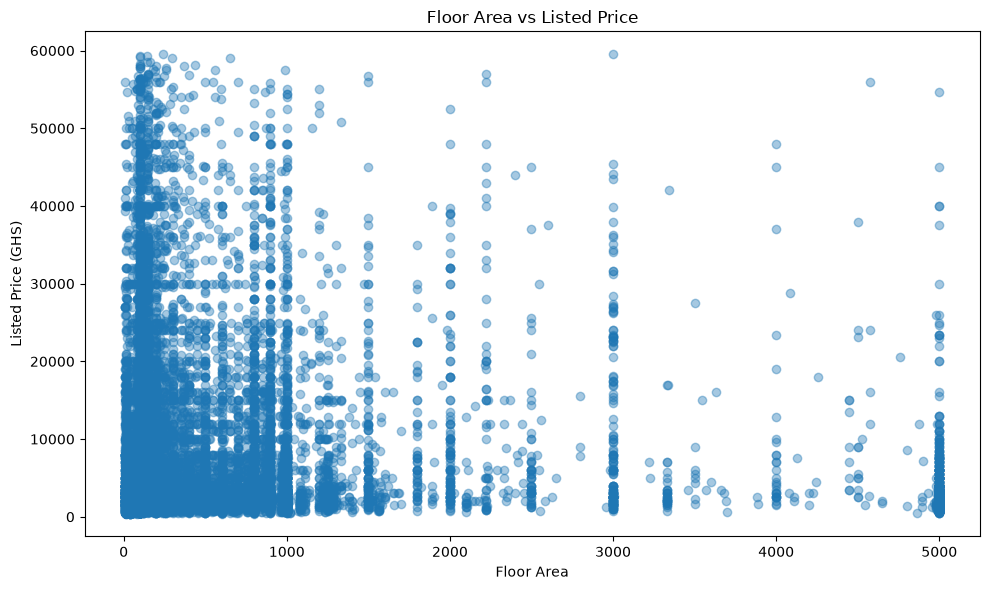

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    df["floor_area"],
    df["price"],
    alpha=0.4
)

plt.xlabel("Floor Area")
plt.ylabel("Listed Price (GHS)")
plt.title("Floor Area vs Listed Price")
plt.tight_layout()
plt.show()

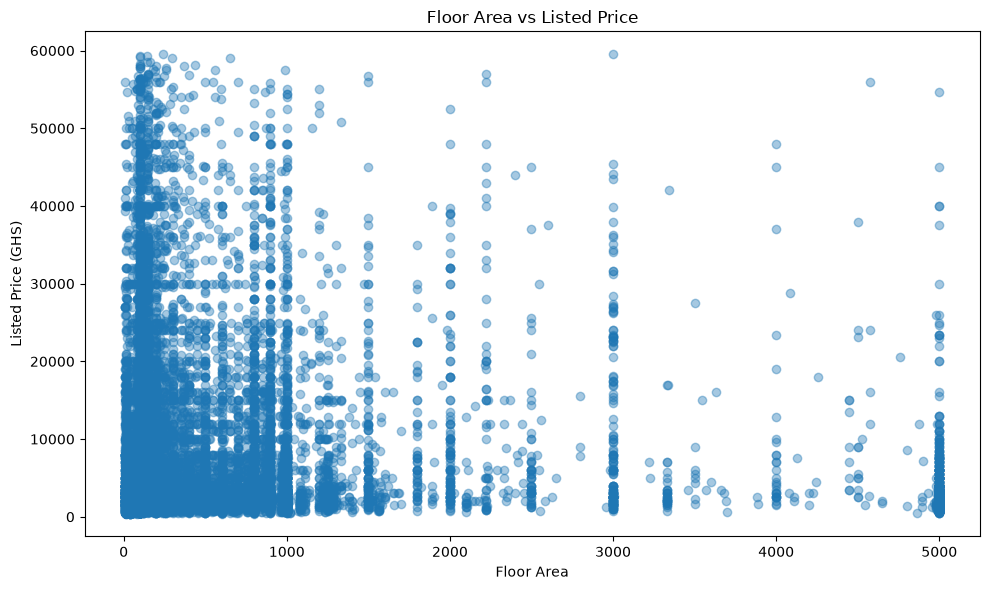

In [21]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["floor_area"],
    df["price"],
    alpha=0.4
)

plt.xlabel("Floor Area")
plt.ylabel("Listed Price (GHS)")
plt.title("Floor Area vs Listed Price")
plt.tight_layout()
plt.show()

In [22]:
print(
    df["floor_area"]
    .value_counts()
    .head(20)
)

floor_area
100.0     3160
200.0      681
150.0      562
14.0       440
1000.0     429
800.0      419
15.0       413
80.0       406
500.0      399
120.0      381
5000.0     375
145.0      368
50.0       315
900.0      283
16.0       281
300.0      279
600.0      278
111.0      272
4999.0     256
400.0      253
Name: count, dtype: int64


In [23]:
print(
    df.groupby(
        pd.cut(df["floor_area"], bins=5)
    )["price"].agg(["count", "mean", "median"])
)

                  count          mean  median
floor_area                                   
(5.01, 1008.0]    15981   8107.652587  3500.0
(1008.0, 2006.0]    802   8293.370324  4000.0
(2006.0, 3004.0]    313  10650.105431  5500.0
(3004.0, 4002.0]     84   6936.309524  3500.0
(4002.0, 5000.0]    710   4188.290141  2500.0


In [26]:
import joblib
from pathlib import Path

MODEL_PATH = Path("../models/rent_price_model.joblib")

print("Model file exists:", MODEL_PATH.exists())
print("Model path:", MODEL_PATH.resolve())

loaded_model = joblib.load(MODEL_PATH)

print("Model loaded successfully!")
print("Model type:", type(loaded_model))

Model file exists: True
Model path: C:\Users\HP\ghana-rent-predictor\models\rent_price_model.joblib
Model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>


In [28]:
print("Training columns:")
print(X_train.columns.tolist())

print("\nNumerical features:")
print(loaded_model.named_steps["preprocessor"].transformers_[0][2])

print("\nCategorical features:")
print(loaded_model.named_steps["preprocessor"].transformers_[1][2])

Training columns:
['listing_type', 'category', 'bedrooms', 'bathrooms', 'floor_area', 'location', 'condition', 'region', 'locality', 'parking_space', 'is_furnished', 'lat', 'lng', 'amenities_count']

Numerical features:
['bedrooms', 'bathrooms', 'floor_area', 'parking_space', 'lat', 'lng', 'amenities_count']

Categorical features:
['listing_type', 'category', 'location', 'condition', 'region', 'locality', 'is_furnished']


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

# Numerical features without floor_area
numerical_features_no_area = [
    "bedrooms",
    "bathrooms",
    "parking_space",
    "lat",
    "lng",
    "amenities_count"
]

# Categorical features remain unchanged
categorical_features = [
    "listing_type",
    "category",
    "location",
    "condition",
    "region",
    "locality",
    "is_furnished"
]

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

# Combine preprocessing
preprocessor_no_area = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features_no_area),
    ("cat", categorical_transformer, categorical_features)
])

In [30]:
model_no_area = Pipeline(steps=[
    ("preprocessor", preprocessor_no_area),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

model_no_area.fit(X_train_no_area, y_train)

predictions_no_area = model_no_area.predict(X_test_no_area)

print("MODEL WITHOUT FLOOR AREA")
print("------------------------")
print(f"MAE: GHS {mean_absolute_error(y_test, predictions_no_area):,.2f}")
print(f"RMSE: GHS {np.sqrt(mean_squared_error(y_test, predictions_no_area)):,.2f}")
print(f"R²: {r2_score(y_test, predictions_no_area):.4f}")

MODEL WITHOUT FLOOR AREA
------------------------
MAE: GHS 3,041.09
RMSE: GHS 5,804.83
R²: 0.7106


In [31]:
original_predictions = loaded_model.predict(X_test)

comparison_results = pd.DataFrame({
    "Model": ["With floor_area", "Without floor_area"],
    "MAE": [
        mean_absolute_error(y_test, original_predictions),
        mean_absolute_error(y_test, predictions_no_area)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, original_predictions)),
        np.sqrt(mean_squared_error(y_test, predictions_no_area))
    ],
    "R2": [
        r2_score(y_test, original_predictions),
        r2_score(y_test, predictions_no_area)
    ]
})

comparison_results

,Model,MAE,RMSE,R2
0,With floor_area,2978.008819,5734.583060,0.717524
1,Without floor_area,3041.085392,5804.828552,0.710562


In [32]:
print("Minimum price:", y_train.min())
print("Contains zero:", (y_train == 0).any())
print("Contains negative values:", (y_train < 0).any())

Minimum price: 416
Contains zero: False
Contains negative values: False


In [33]:
from sklearn.base import clone
import numpy as np

# Create a fresh copy of the original trained pipeline's configuration
log_model = clone(loaded_model)

# Transform training prices
y_train_log = np.log1p(y_train)

# Train using transformed prices
log_model.fit(X_train, y_train_log)

# Predict transformed prices
predictions_log = log_model.predict(X_test)

# Convert predictions back to GHS
predictions_log_ghs = np.expm1(predictions_log)

print("Log-transformed model trained successfully!")
print("Sample predictions:", predictions_log_ghs[:10])

Log-transformed model trained successfully!
Sample predictions: [2181.83912768 2776.32982817  833.46417494 1172.5748723  3866.08271229
 3486.1872381  4416.11293476 3845.33667608 9127.33783521  792.3122909 ]


In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

log_mae = mean_absolute_error(y_test, predictions_log_ghs)

log_rmse = np.sqrt(
    mean_squared_error(y_test, predictions_log_ghs)
)

log_r2 = r2_score(y_test, predictions_log_ghs)

print("LOG-TRANSFORMED MODEL RESULTS")
print("-----------------------------")
print(f"MAE: GHS {log_mae:,.2f}")
print(f"RMSE: GHS {log_rmse:,.2f}")
print(f"R²: {log_r2:.4f}")

LOG-TRANSFORMED MODEL RESULTS
-----------------------------
MAE: GHS 2,947.25
RMSE: GHS 5,948.73
R²: 0.6960


In [35]:
model_comparison = pd.DataFrame({
    "Model": [
        "Original Model",
        "Log-Transformed Model"
    ],
    "MAE": [
        mean_absolute_error(y_test, original_predictions),
        log_mae
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, original_predictions)),
        log_rmse
    ],
    "R2": [
        r2_score(y_test, original_predictions),
        log_r2
    ]
})

model_comparison

,Model,MAE,RMSE,R2
0,Original Model,2978.008819,5734.583060,0.717524
1,Log-Transformed Model,2947.249544,5948.729023,0.696034


In [36]:
# Create a comparison dataframe
error_analysis = pd.DataFrame({
    "Actual Price": y_test,
    "Original Prediction": original_predictions,
    "Log Prediction": predictions_log_ghs
})

# Calculate absolute errors
error_analysis["Original Error"] = (
    error_analysis["Actual Price"] -
    error_analysis["Original Prediction"]
).abs()

error_analysis["Log Error"] = (
    error_analysis["Actual Price"] -
    error_analysis["Log Prediction"]
).abs()

# Group listings by actual price
error_analysis["Price Group"] = pd.cut(
    error_analysis["Actual Price"],
    bins=[0, 2000, 5000, 10000, 20000, 60000],
    labels=[
        "Below 2,000",
        "2,000–5,000",
        "5,000–10,000",
        "10,000–20,000",
        "Above 20,000"
    ]
)

# Calculate average errors for each group
group_comparison = error_analysis.groupby(
    "Price Group",
    observed=False
)[["Original Error", "Log Error"]].mean()

group_comparison

,Original Error,Log Error
Price Group,,
"Below 2,000",594.736992,461.833943
"2,000–5,000",1506.243458,1164.334773
"5,000–10,000",3368.066409,2906.028219
"10,000–20,000",5036.344699,5168.606630
"Above 20,000",11188.439066,12743.359188


In [37]:
error_analysis["Original Residual"] = (
    error_analysis["Actual Price"] -
    error_analysis["Original Prediction"]
)

error_analysis["Log Residual"] = (
    error_analysis["Actual Price"] -
    error_analysis["Log Prediction"]
)

bias_comparison = error_analysis.groupby(
    "Price Group",
    observed=False
)[["Original Residual", "Log Residual"]].mean()

bias_comparison

,Original Residual,Log Residual
Price Group,,
"Below 2,000",-462.488665,-297.534034
"2,000–5,000",-1018.257855,-519.056615
"5,000–10,000",-1716.235060,-569.640176
"10,000–20,000",-264.449385,1332.167816
"Above 20,000",8438.255703,10742.888293


In [39]:
# Display the names of all steps in the saved pipeline
print(loaded_model.named_steps)

# Display only the step names
print(loaded_model.named_steps.keys())

{'preprocessor': ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['bedrooms', 'bathrooms', 'floor_area',
                                  'parking_space', 'lat', 'lng',
                                  'amenities_count']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                min_frequency=10))]),
                                 ['listing_type', 'category', 'location',
                     

In [40]:
import pandas as pd
import matplotlib.pyplot as plt

# Access the trained Random Forest model
random_forest = loaded_model.named_steps["model"]

# Access the preprocessing component
preprocessor = loaded_model.named_steps["preprocessor"]

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get Random Forest importance scores
importance_scores = random_forest.feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 20 features
feature_importance.head(20)

,Feature,Importance
1,num__bathrooms,0.274137
204,cat__is_furnished_Furnished,0.142198
5,num__lng,0.102149
6,num__amenities_count,0.089267
4,num__lat,0.085477
2,num__floor_area,0.072918
0,num__bedrooms,0.068519
154,cat__locality_Cantonments,0.048794
10,cat__category_Flats,0.010651
160,cat__locality_East Legon,0.009113


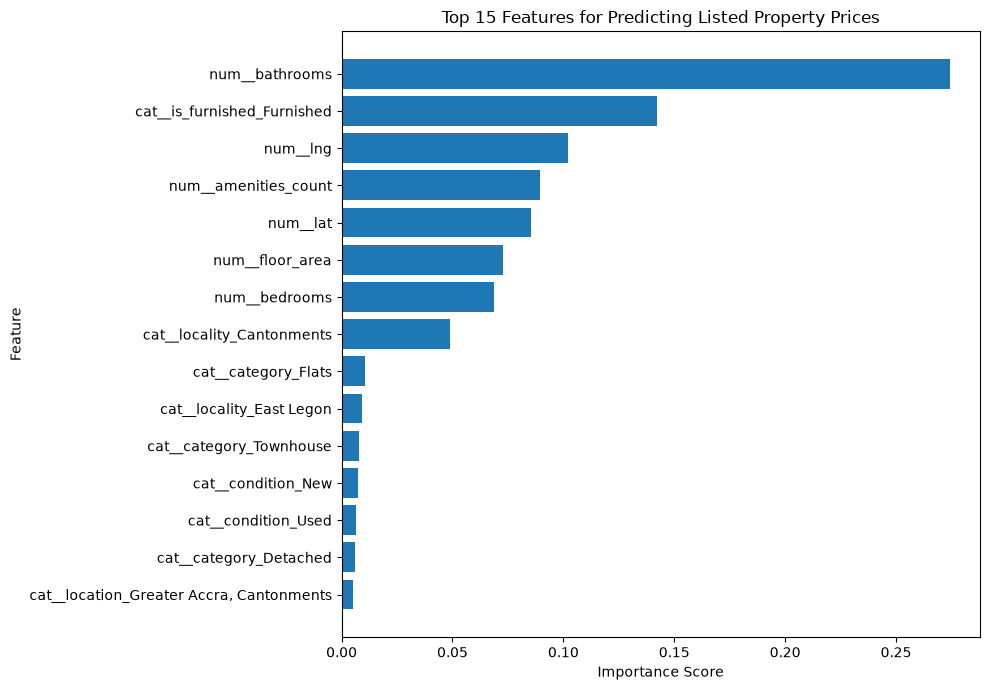

In [41]:
top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 15 Features for Predicting Listed Property Prices")

plt.tight_layout()
plt.show()

In [42]:
from sklearn.inspection import permutation_importance

permutation_results = permutation_importance(
    loaded_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": permutation_results.importances_mean,
    "Std": permutation_results.importances_std
})

permutation_importance_df = permutation_importance_df.sort_values(
    by="Importance",
    ascending=False
)

permutation_importance_df

,Feature,Importance,Std
10,is_furnished,9.749388e+02,3.401073e+01
11,lat,9.383228e+02,6.512575e+01
3,bathrooms,9.209115e+02,5.609582e+00
12,lng,9.043350e+02,3.793842e+01
13,amenities_count,6.104816e+02,2.021228e+01
2,bedrooms,6.102444e+02,2.546900e+01
8,locality,3.440398e+02,2.727470e+01
4,floor_area,2.505528e+02,1.928289e+01
1,category,2.216914e+02,1.266716e+01
6,condition,5.058898e+01,5.847640e+00


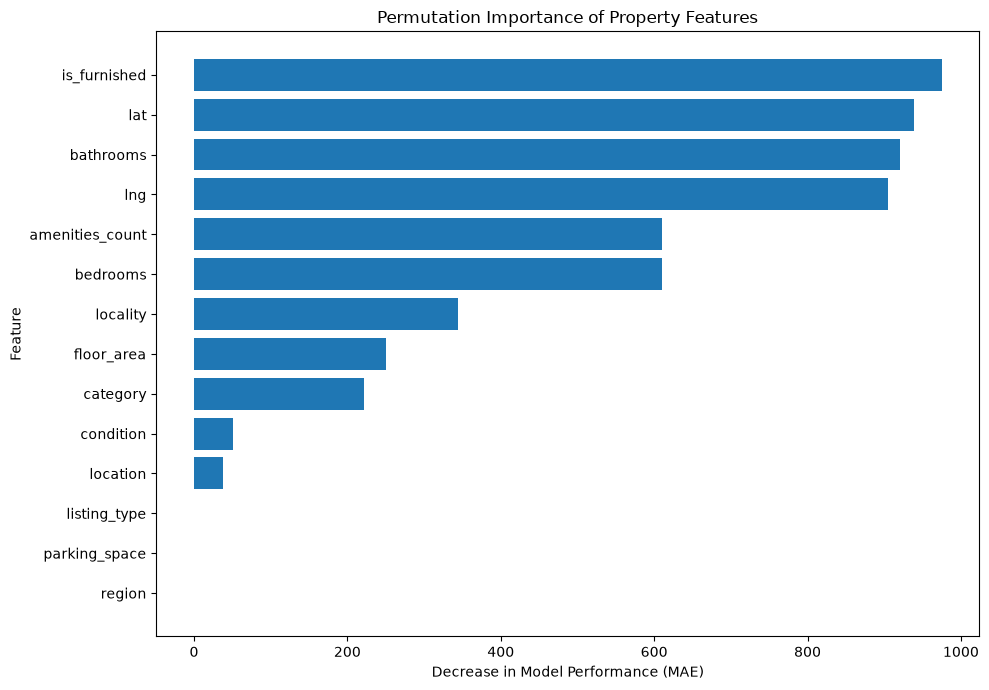

In [43]:
top_permutation = permutation_importance_df.head(14).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_permutation["Feature"],
    top_permutation["Importance"]
)

plt.xlabel("Decrease in Model Performance (MAE)")
plt.ylabel("Feature")
plt.title("Permutation Importance of Property Features")

plt.tight_layout()
plt.show()

In [45]:
evaluation_df = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": original_predictions
})

evaluation_df["Residual"] = (
    evaluation_df["Actual Price"] -
    evaluation_df["Predicted Price"]
)

evaluation_df["Absolute Error"] = (
    evaluation_df["Residual"].abs()
)

evaluation_df.head(10)

,Actual Price,Predicted Price,Residual,Absolute Error
0,2000,1955.642100,44.357900,44.357900
1,2500,3339.800992,-839.800992,839.800992
2,1500,851.361131,648.638869,648.638869
3,1000,1227.446825,-227.446825,227.446825
4,4000,5097.299397,-1097.299397,1097.299397
5,3500,3483.899167,16.100833,16.100833
6,5000,4433.563492,566.436508,566.436508
7,3000,4180.392063,-1180.392063,1180.392063
8,8000,12823.683464,-4823.683464,4823.683464
9,1200,829.357143,370.642857,370.642857


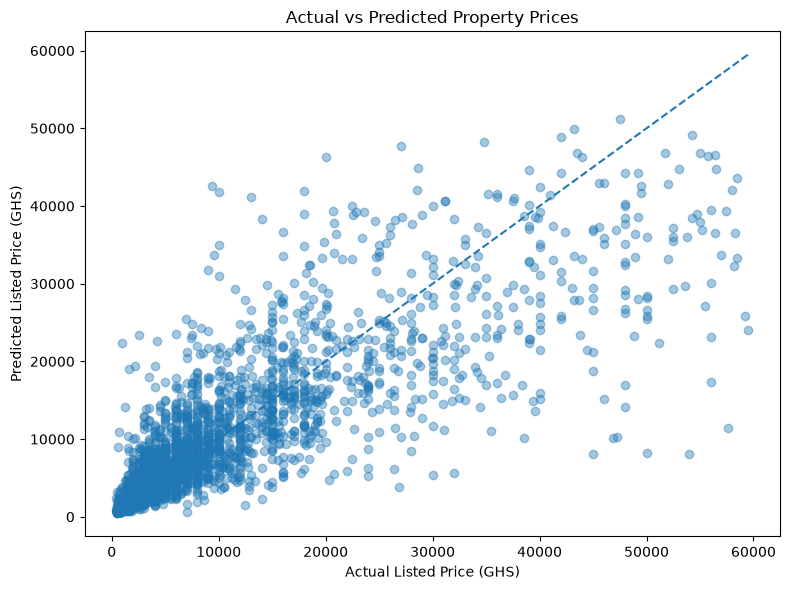

In [46]:
plt.figure(figsize=(8, 6))

plt.scatter(
    evaluation_df["Actual Price"],
    evaluation_df["Predicted Price"],
    alpha=0.4
)

min_price = min(
    evaluation_df["Actual Price"].min(),
    evaluation_df["Predicted Price"].min()
)

max_price = max(
    evaluation_df["Actual Price"].max(),
    evaluation_df["Predicted Price"].max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Listed Price (GHS)")
plt.ylabel("Predicted Listed Price (GHS)")
plt.title("Actual vs Predicted Property Prices")

plt.tight_layout()
plt.show()

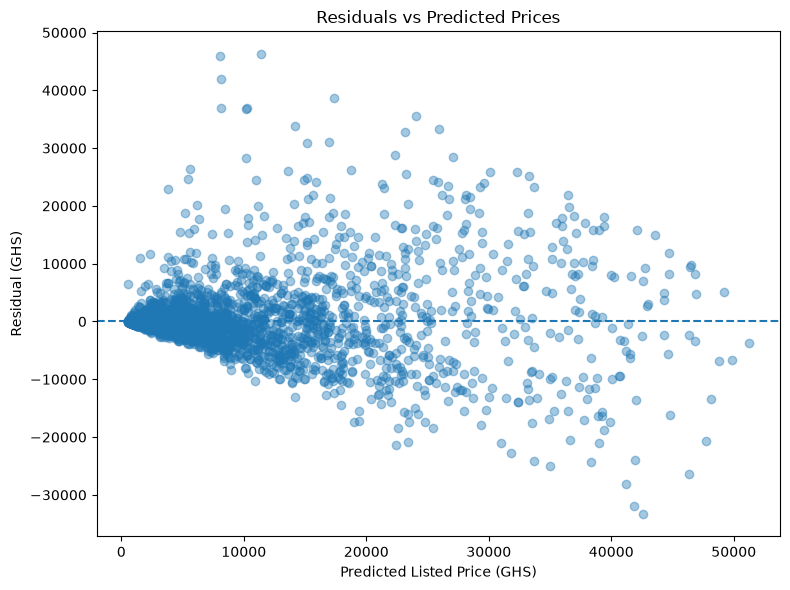

In [47]:
plt.figure(figsize=(8, 6))

plt.scatter(
    evaluation_df["Predicted Price"],
    evaluation_df["Residual"],
    alpha=0.4
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Listed Price (GHS)")
plt.ylabel("Residual (GHS)")
plt.title("Residuals vs Predicted Prices")

plt.tight_layout()
plt.show()

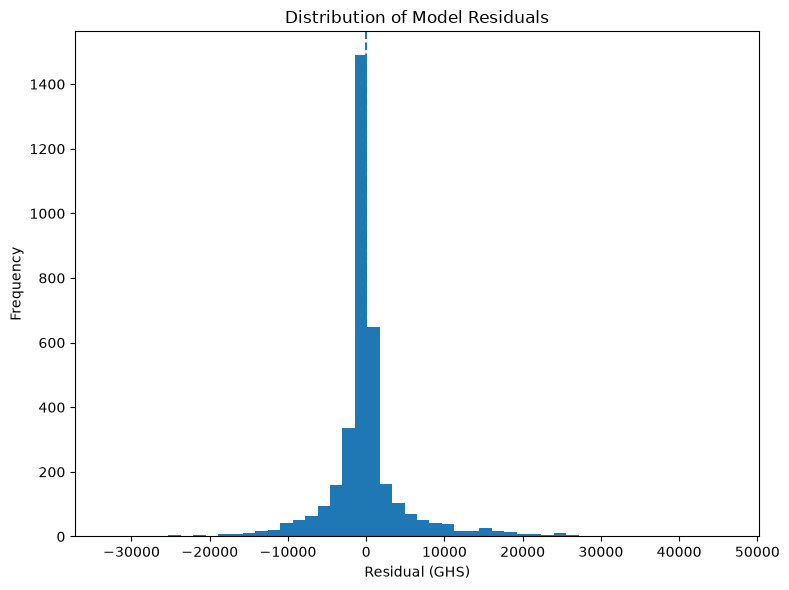

In [48]:
plt.figure(figsize=(8, 6))

plt.hist(
    evaluation_df["Residual"],
    bins=50
)

plt.axvline(x=0, linestyle="--")

plt.xlabel("Residual (GHS)")
plt.ylabel("Frequency")
plt.title("Distribution of Model Residuals")

plt.tight_layout()
plt.show()

In [49]:
evaluation_df["Price Group"] = pd.cut(
    evaluation_df["Actual Price"],
    bins=[0, 2000, 5000, 10000, 20000, float("inf")],
    labels=[
        "Below 2,000",
        "2,000–5,000",
        "5,000–10,000",
        "10,000–20,000",
        "Above 20,000"
    ],
    right=False
)

price_group_results = (
    evaluation_df.groupby("Price Group", observed=False)
    .agg(
        Listings=("Actual Price", "count"),
        MAE=("Absolute Error", "mean"),
        Mean_Residual=("Residual", "mean")
    )
    .reset_index()
)

price_group_results

,Price Group,Listings,MAE,Mean_Residual
0,"Below 2,000",980,552.508608,-430.526379
1,"2,000–5,000",1098,1344.147881,-924.507928
2,"5,000–10,000",618,3028.432465,-1572.933361
3,"10,000–20,000",491,4960.564323,-423.737350
4,"Above 20,000",391,11076.149359,8128.549352


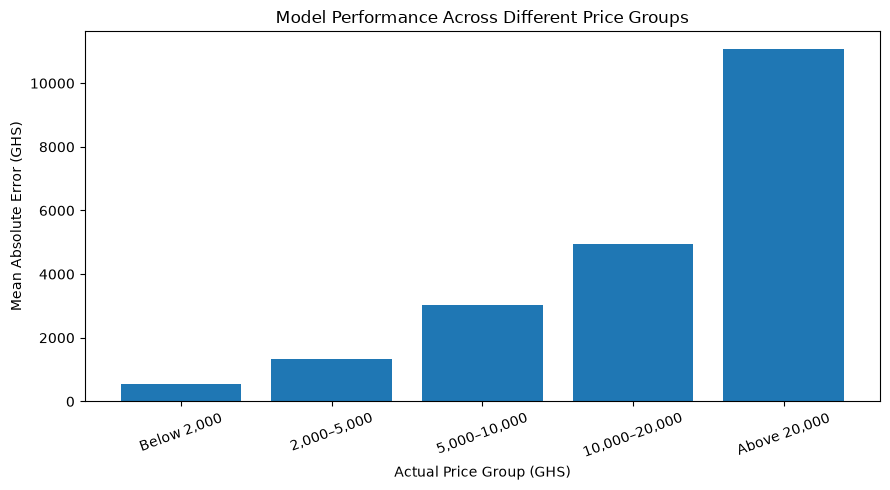

In [50]:
plt.figure(figsize=(9, 5))

plt.bar(
    price_group_results["Price Group"].astype(str),
    price_group_results["MAE"]
)

plt.xlabel("Actual Price Group (GHS)")
plt.ylabel("Mean Absolute Error (GHS)")
plt.title("Model Performance Across Different Price Groups")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [53]:
final_metrics = {
    "model": "Random Forest Regressor",
    "mae": 2978.01,
    "mse": 32885442.88,
    "rmse": 5734.58,
    "r2": 0.7175,
    "training_records": 14312,
    "testing_records": 3578
}

print(final_metrics)

{'model': 'Random Forest Regressor', 'mae': 2978.01, 'mse': 32885442.88, 'rmse': 5734.58, 'r2': 0.7175, 'training_records': 14312, 'testing_records': 3578}


In [54]:
from pathlib import Path
import json

metrics_dir = Path("../reports/metrics")
metrics_dir.mkdir(parents=True, exist_ok=True)

# Save evaluation metrics
with open(metrics_dir / "model_evaluation.json", "w") as file:
    json.dump(final_metrics, file, indent=4)

# Save feature importance
feature_importance.to_csv(
    metrics_dir / "feature_importance.csv",
    index=False
)

# Save permutation importance
permutation_importance_df.to_csv(
    metrics_dir / "permutation_importance.csv",
    index=False
)

# Save performance across price groups
price_group_results.to_csv(
    metrics_dir / "price_group_performance.csv",
    index=False
)

# Save actual and predicted prices
evaluation_df.to_csv(
    metrics_dir / "test_predictions.csv",
    index=False
)

print("All evaluation results saved successfully!")

All evaluation results saved successfully!


In [55]:
from sklearn.model_selection import cross_validate

cv_results = cross_validate(
    loaded_model,
    X,
    y,
    cv=5,
    scoring={
        "mae": "neg_mean_absolute_error",
        "r2": "r2"
    },
    n_jobs=-1
)

cv_mae = -cv_results["test_mae"]
cv_r2 = cv_results["test_r2"]

print("Cross-validation MAE:", cv_mae)
print("Mean MAE:", cv_mae.mean())
print("MAE Standard Deviation:", cv_mae.std())

print("\nCross-validation R2:", cv_r2)
print("Mean R2:", cv_r2.mean())

Cross-validation MAE: [2827.38726317 2995.77089272 2890.83197209 2940.92146703 2799.56847644]
Mean MAE: 2890.896014289737
MAE Standard Deviation: 71.93798827993844

Cross-validation R2: [0.71305615 0.73813772 0.7219316  0.72776515 0.72392465]
Mean R2: 0.7249630518942061


In [56]:
final_metrics.update({
    "cross_validation_mae_mean": 2890.90,
    "cross_validation_mae_std": 71.94,
    "cross_validation_r2_mean": 0.7250
})